In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

from wavelets import WaveletTransformOperator2D

import jlinops




from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])




from msolver import IASGKS, MMGKS, VanillaGKS
from fsolver import MMFGK, IASFGK
from pgkbsolver import MMGKB, IASGKB

# Setup toy problem

In [2]:
image = jlinops.cameraman()
img_shape = image.shape
ground_truth = image.flatten()

A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="reflect")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ ground_truth
noise_level_sigma = 0.03
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
noise_sigma = np.sqrt(noise_var)
b = b_true + noise_vec
naive_recon = A.T @ b

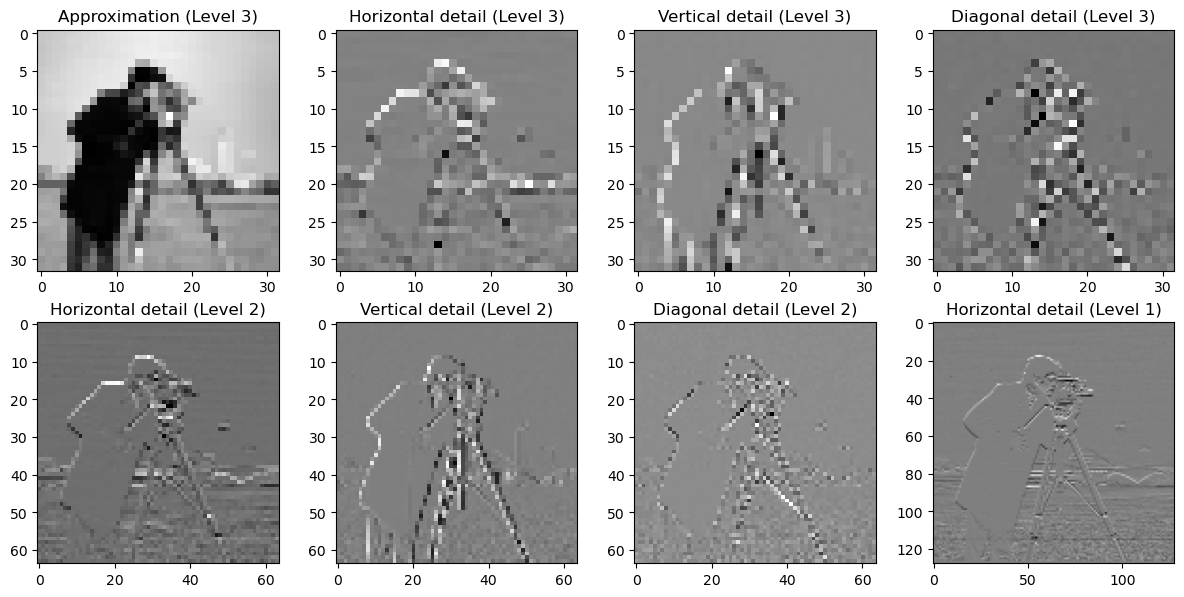

In [3]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


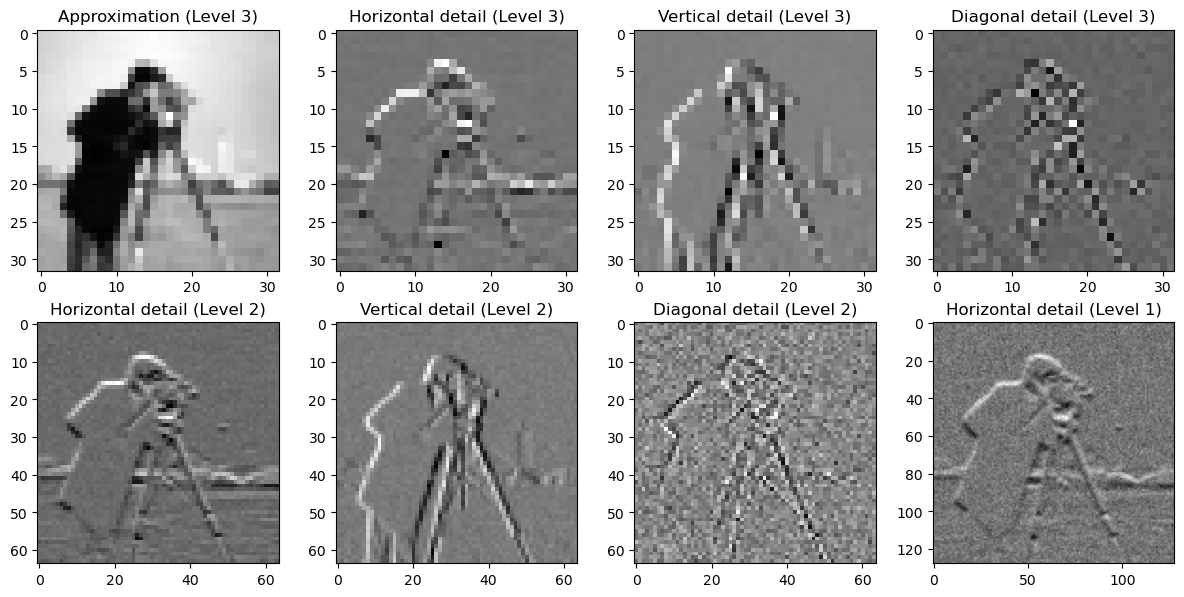

In [4]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


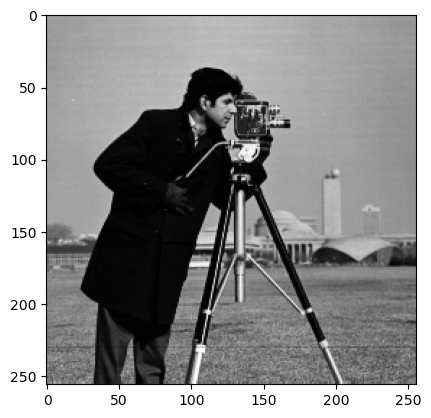

In [5]:
plt.imshow(image, cmap="gray")
plt.show()

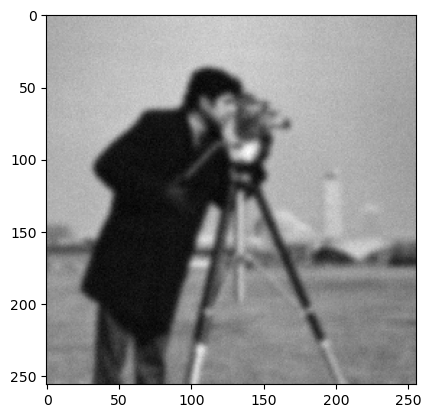

In [6]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Set up prior

In [7]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

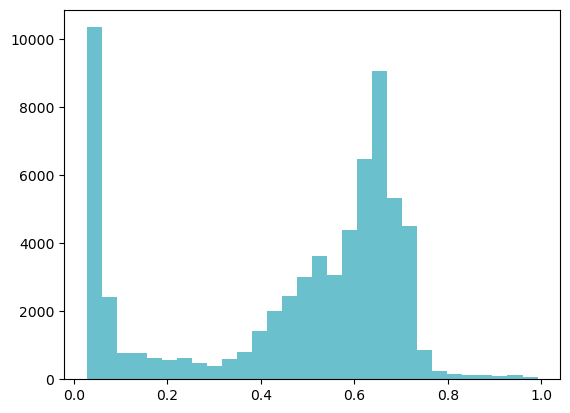

In [8]:
plt.hist(ground_truth, bins=30)
plt.show()

In [9]:
# Set method
method = "dp"

# Weight params
weight_params = {
    "hyperpr_r": -1,
    "hyperpr_beta": 1,
}

# Build solver
mmgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

xker = None
ground_truth = ground_truth.copy()

In [10]:
n_its = 130

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params, 
                                                 regparam_kwargs={"eta":1.01})


data = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


mmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


rmmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )



mmgkbdata = mmgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")



7.992748084486573
24.82885340646778
30.993189829642656
34.55670659389925
36.75973339934021
38.20069065070915
39.19407772975076
39.89804616910466
40.38276932674521
40.73049931600805
40.9839105062664
41.169500635561455
41.304637836354964
41.40371605973316
41.472240462365185
41.52147371143856
41.55647633290192
41.58154653271245
41.599271014439516
41.61194985105537
41.621097383428236
41.6271518198492
41.63131351866278
41.634252903551435
41.63627973855489
41.63768881306524
41.63868632490598
41.63938823776126
41.63986539479827
41.640200852312724
41.640427542163565
41.64058890936372
41.6407021094222
41.64078001651124
41.64083398722699
41.640870679185944
41.64089650099742
41.64091447547869
41.640926586285346
41.64093444235915
41.64094005774583
41.64094400565129
41.64094669270262
41.64094849219542
41.64094975346496
41.64095061893602
41.640951216460564
41.64095161624486
41.64095189196252
41.640952079384526
41.64095220734964
41.640952297191184
41.640952358677204
41.64095239948901
41.6409524272968

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_wavelets/../../msolver.py:800: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
6.671086053372674
1e-07
10.868956811434687
1e-07
12.90488990655893
1e-07
14.188273054717765
1e-07
15.019766943565065
1e-07
15.585434929909827
1e-07
15.991180150759897
1e-07
16.27407317874711
1e-07
16.45217797049809
1e-07
16.552209801540606
1e-07
16.617361202000975
1e-07
16.659428612630336
1e-07
16.685626047199566
1e-07
16.70349783075888
1e-07
16.705582417244074
1e-07
16.702280213525516
40.19641589916629
1e-07
16.695272073414433
71.51840665915255
1e-07
16.687726321327887
82.28002637117375
1e-07
16.682380782245446
88.2916621314374
1e-07
16.678227614213025
92.455105147172
1e-07
16.67457628995392
96.27039736150599
1e-07
16.67056031841048
99.61957153090812
1e-07
16.668118185063094
102.75757901147254
1e-07
16.666119791954735
105.13032848602664
1e-07
16.664347037322795
107.38185967364366
1e-07
16.662565448258885
109.53379088325435
1e-07
16.66086512480863
111.44747142708043
1e-07
16.659866778776692
113.07703500683733
1e-07
16.658969308615312
114.25015516326738
1e-07
16.

64.11218225921132
174.24066004042177
174.19237874487646
169.99525586282215
210.95732482677266
272.13688938170026
294.0328610311071
304.9154419303996
302.25852093855025
298.69577853715964
295.9551415718013
291.1566065100671
286.57992057649506
286.42944984181827
285.9699948618552
281.7736170726647
279.6382128428157
281.66971462854417
281.3658430812399
277.969771621777
279.2602916562063
282.86978338967805
284.20183823961
283.509347437966
284.5869335470118
285.27770310013244
285.60523660619543
286.34974548874914
287.4813401796369
287.53737894542786
287.33498845266905
287.43299301775767
287.7082904144704
287.82407308912497
287.59092998498136
287.5957279228698
287.7424862512164
287.3268503649757
286.47547759619437
286.0413811285078
285.6555345429827
285.19598526364484
284.74418709001674
284.45959509655756
284.0885527483264
283.7447137610798
283.41751142697296
282.6614498707117
282.38299970965
280.7150102638673
280.3398145007661
280.5365649034419
280.5419450195302
280.4207682065481
280.333593

...

16.656544773096062


generating basis...: 100%|██████████| 129/129 [00:02<00:00, 56.67it/s]

123.5679939120007



generating basis...: 100%|██████████| 130/130 [00:02<00:00, 54.00it/s]


153.76845331885758
Finished P-GKB


# Performance

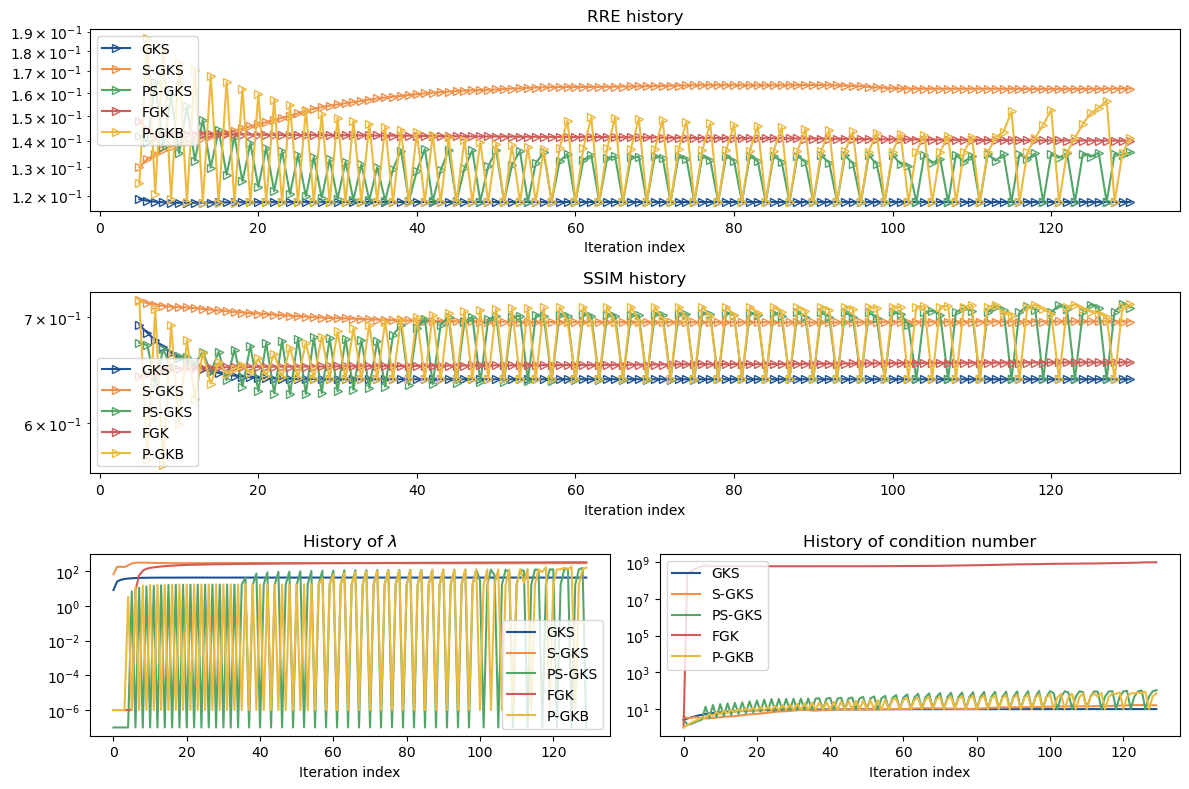

In [14]:
fig = plt.figure(figsize=(12,8) )

gs = gridspec.GridSpec(3, 2, figure=fig)

start_idx = 5
marker = ">"
markerfacecolor = 'none'

ax4 = fig.add_subplot(gs[0, :])
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))],  vdata["rre_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["rre_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["rre_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["rre_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["rre_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax4.legend()
ax4.set_xlabel("Iteration index")
ax4.set_title("RRE history")



ax3 = fig.add_subplot(gs[1, :])
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], vdata["ssim_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["ssim_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["ssim_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["ssim_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["ssim_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax3.legend()
ax3.set_xlabel("Iteration index")
ax3.set_title("SSIM history")

# ax3 = fig.add_subplot(gs[1, :])
# ax3.semilogy(vdata["haar_history"][start_idx:], label="GKS")
# ax3.semilogy(data["haar_history"][start_idx:], label="S-GKS")
# ax3.semilogy(pdata["haar_history"][start_idx:], label="PS-GKS")
# ax3.semilogy(mmfkdata["haar_history"][start_idx:], label="FGK")
# ax3.semilogy(mmgkbdata["haar_history"][start_idx:], label="P-GKB")
# ax3.legend()


ax1 = fig.add_subplot(gs[2, 0])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(mmfkdata["lambda_history"], label="FGK", color="C6")
ax1.semilogy(mmgkbdata["lambda_history"], label="P-GKB", color="C1")
ax1.legend(loc="lower right")
ax1.set_title("History of $\lambda$")
ax1.set_xlabel("Iteration index")



ax2 = fig.add_subplot(gs[2, 1])
ax2.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax2.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax2.semilogy(pdata["cond_ests"], label="PS-GKS", color="C4")
ax2.semilogy(mmfkdata["cond_ests"], label="FGK", color="C6")
ax2.semilogy(mmgkbdata["cond_ests"], label="P-GKB", color="C1")
ax2.legend(loc="upper left")
ax2.set_title("History of condition number")
ax2.set_xlabel("Iteration index")

fig.tight_layout()
fig.savefig("2d_camera_performance_ias.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_performance_ias.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Reconstructions

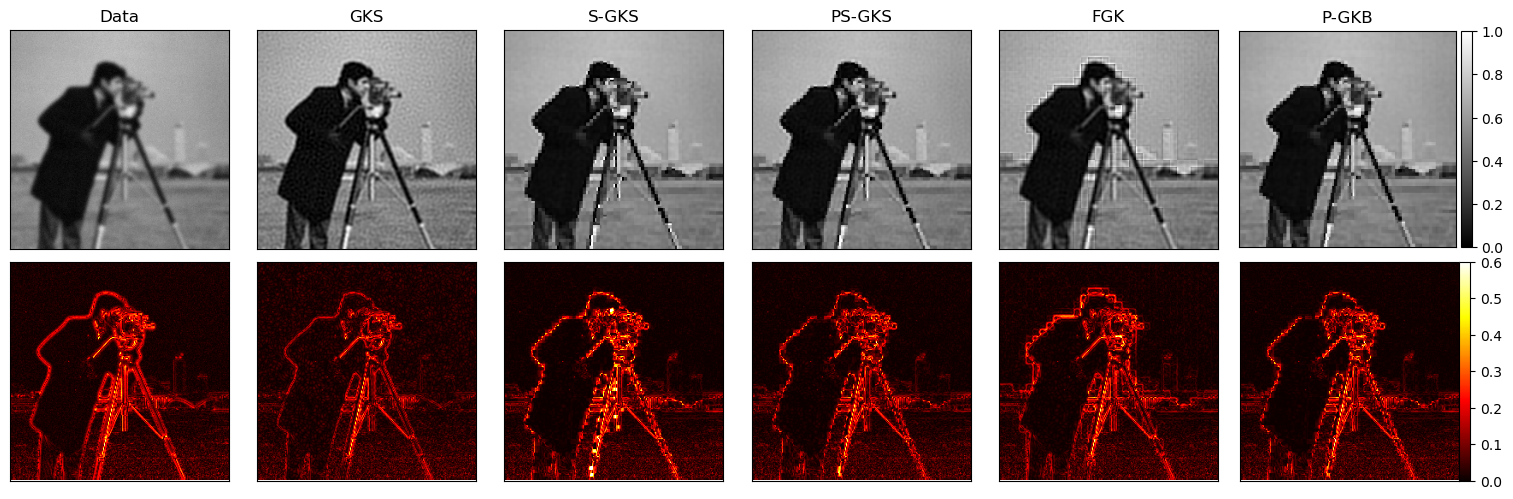

In [16]:
err_cmap = "hot"

vbound = 0.6

fig, axs = plt.subplots(2,6,figsize=(15.3,5))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,1].set_title("GKS")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,2].set_title("S-GKS")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,4].set_title("FGK")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# PS-GKS restarting
im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,5].set_title("P-GKB")
axs[0,5].set_xticks([])
axs[0,5].set_yticks([])
divider = make_axes_locatable(axs[0,5])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,5].set_xticks([])
axs[1,5].set_yticks([])
divider = make_axes_locatable(axs[1,5])
cax = divider.append_axes("right", size="5%", pad=0.00)
fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_camera_reconstructions_ias.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_reconstructions_ias.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Basis vectors

In [11]:
np.amax(np.abs(data["V"][:,:]))

0.13033640708927305

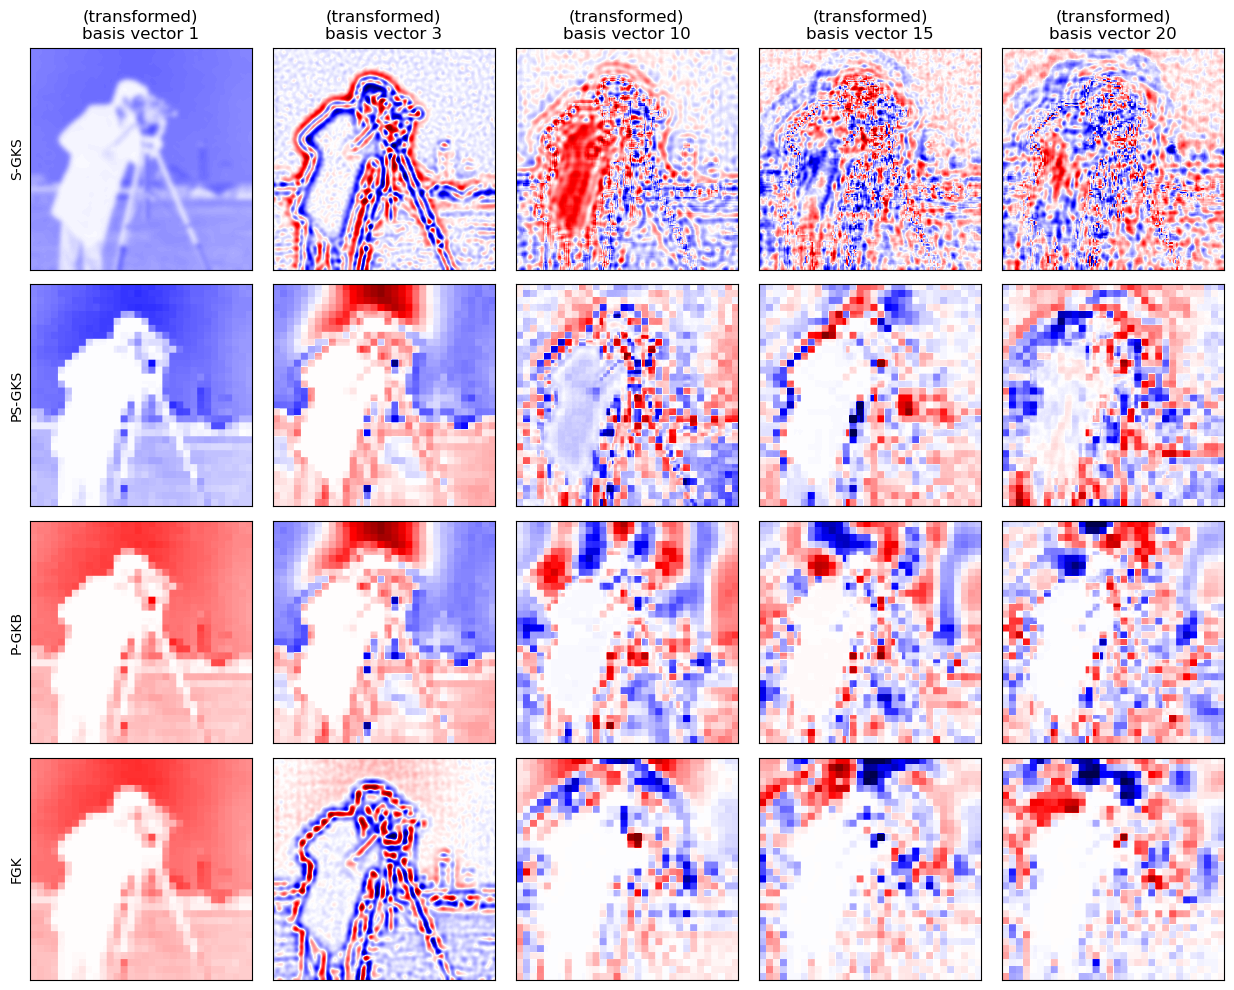

In [12]:
cmap = "seismic"
vbound = 0.1*0.189

kks = [0, 2, 9, 14, 19]

fig, axs = plt.subplots(4,5,figsize=(12.5,10))

for j, kk in enumerate(kks):

    axs[0,j].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[0,j].set_title(f"S-GKS basis vector {kk+1}")
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    if j == 0:
        axs[0,0].set_ylabel(f"S-GKS")
    axs[0,j].set_title(f"(transformed)\nbasis vector {kk+1}")


for j, kk in enumerate(kks):

    axs[1,j].imshow( ( (pdata["Lopinv"] @ pdata["V"][:,kk])/np.linalg.norm(pdata["Lopinv"] @ pdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
    if j == 0:
        axs[1,j].set_ylabel(f"PS-GKS")


for j, kk in enumerate(kks):

    axs[2,j].imshow( ( (mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk])/np.linalg.norm(mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
    if j == 0:
        axs[2,j].set_ylabel(f"P-GKB")



for j, kk in enumerate(kks):

    axs[3,j].imshow( ( mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
    if j == 0:
        axs[3,j].set_ylabel(f"FGK")


fig.tight_layout()

fig.savefig("2d_camera_basis_vectors_ias.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_basis_vectors_ias.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Other plots

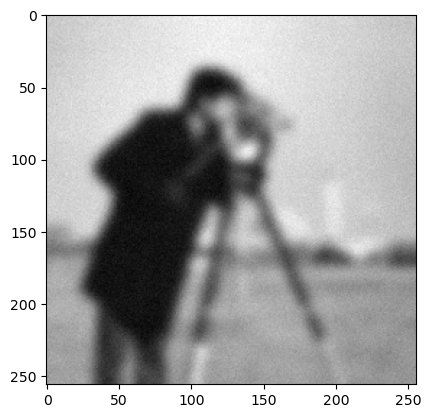

In [135]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

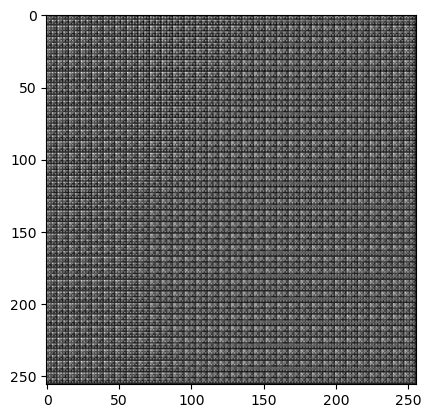

In [136]:
plt.imshow( (L.T @ b).reshape(img_shape), cmap="gray")
plt.show()

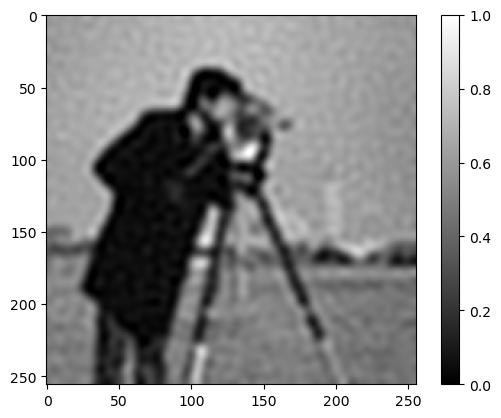

In [116]:
plt.imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

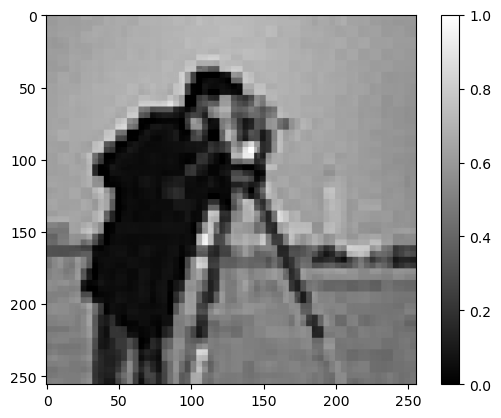

In [117]:
plt.imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

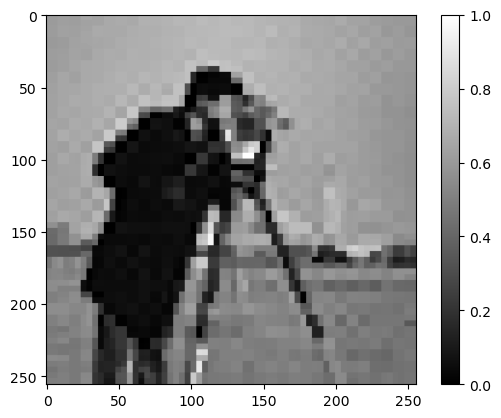

In [118]:
plt.imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

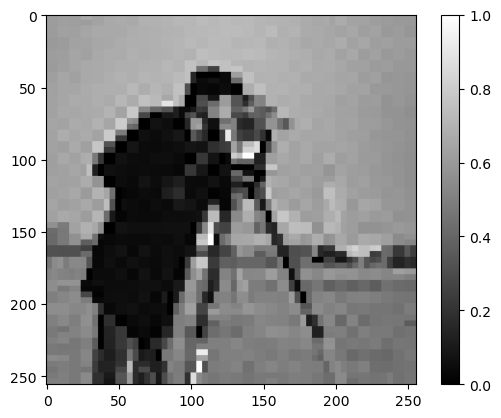

In [119]:
plt.imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

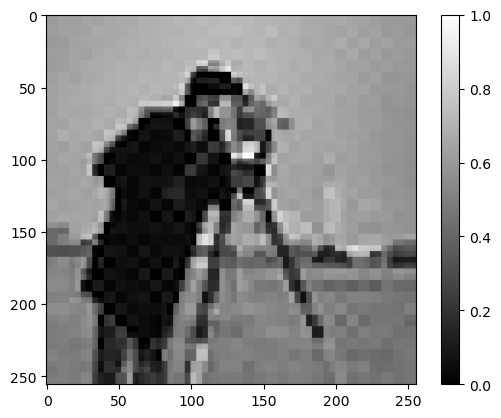

In [120]:
plt.imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

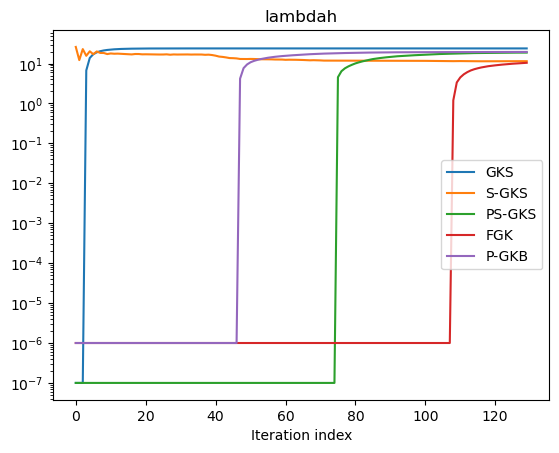

In [121]:
plt.semilogy(vdata["lambda_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["lambda_history"], label="PS-GKS")
plt.semilogy(mmfkdata["lambda_history"], label="FGK")
plt.semilogy(mmgkbdata["lambda_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("lambdah")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

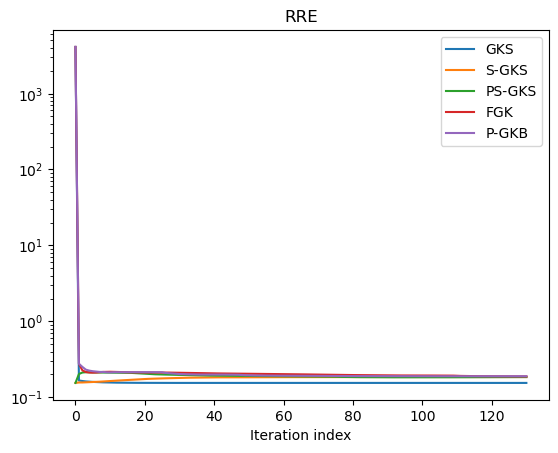

In [122]:
plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["rre_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["rre_history"], label="PS-GKS")
plt.semilogy(mmfkdata["rre_history"], label="FGK")
plt.semilogy(mmgkbdata["rre_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

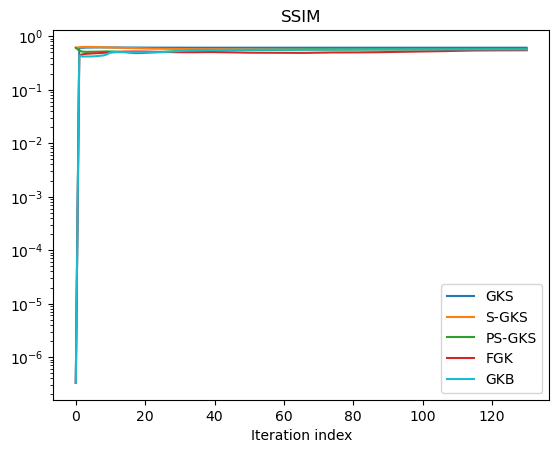

In [125]:
plt.semilogy(vdata["ssim_history"], label="GKS")
plt.semilogy(data["ssim_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["ssim_history"], label="PS-GKS")
plt.semilogy(mmfkdata["ssim_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmgkbdata["ssim_history"], label="GKB", color="C9")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

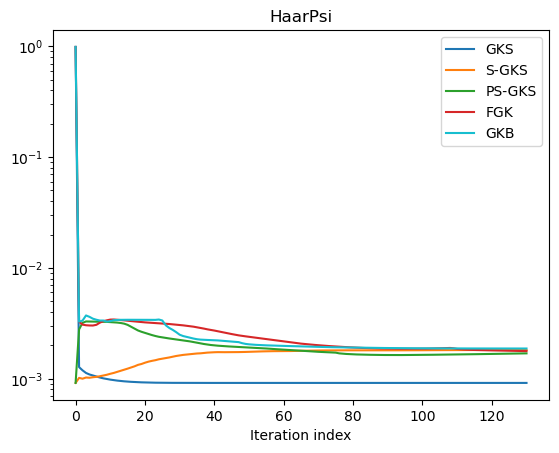

In [126]:
plt.semilogy(1-vdata["haar_history"], label="GKS")
plt.semilogy(1-data["haar_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(1-pdata["haar_history"], label="PS-GKS")
plt.semilogy(1-mmfkdata["haar_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(1-mmgkbdata["haar_history"], label="GKB", color="C9")
plt.title("HaarPsi")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [24]:
pdata["haar_history"]

array([0.99977895, 0.99893879, 0.99877378, 0.99870822, 0.99871015,
       0.9987684 , 0.99883229, 0.99887182, 0.99890467, 0.99893616,
       0.99896992, 0.99899804, 0.99902043, 0.99904554, 0.99907053,
       0.99909251, 0.99911082, 0.99912711, 0.99914394, 0.99916236,
       0.99918311, 0.99920906, 0.99923647, 0.99926293, 0.99928414,
       0.9993028 , 0.99932018, 0.99933764, 0.99935618, 0.99937194,
       0.99938765, 0.99940613, 0.99942366, 0.99944045, 0.99945714,
       0.99947115, 0.99948362, 0.99949556, 0.99950773, 0.99951852,
       0.99952721, 0.99953537, 0.99954417, 0.99955255, 0.99956083,
       0.99956818, 0.99957536, 0.99958231, 0.9995889 , 0.99959529,
       0.99960063, 0.99960472, 0.99960906, 0.99961346, 0.99961734,
       0.99962098, 0.99962459, 0.99962742, 0.99962972, 0.9996319 ,
       0.99963382, 0.99963526, 0.99963669, 0.99963862, 0.99964097,
       0.99964298, 0.99964476, 0.99964625, 0.99964718, 0.99964826,
       0.99965394, 0.99966057, 0.99966447, 0.99966765, 0.99967

In [25]:
vdata["haar_history"]

array([9.31203851e-04, 9.99680055e-01, 9.99707518e-01, 9.99728855e-01,
       9.99744216e-01, 9.99755268e-01, 9.99762842e-01, 9.99768336e-01,
       9.99772198e-01, 9.99774815e-01, 9.99776571e-01, 9.99777668e-01,
       9.99778344e-01, 9.99778713e-01, 9.99778885e-01, 9.99778956e-01,
       9.99778968e-01, 9.99778972e-01, 9.99778982e-01, 9.99779013e-01,
       9.99779031e-01, 9.99779029e-01, 9.99779020e-01, 9.99779011e-01,
       9.99779003e-01, 9.99778992e-01, 9.99778986e-01, 9.99778977e-01,
       9.99778971e-01, 9.99778966e-01, 9.99778962e-01, 9.99778960e-01,
       9.99778961e-01, 9.99778962e-01, 9.99778961e-01, 9.99778960e-01,
       9.99778958e-01, 9.99778957e-01, 9.99778955e-01, 9.99778954e-01,
       9.99778953e-01, 9.99778952e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
      

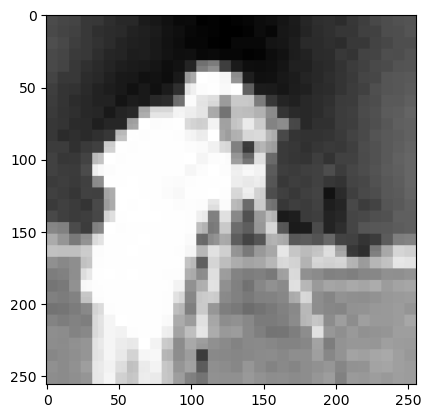

In [127]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

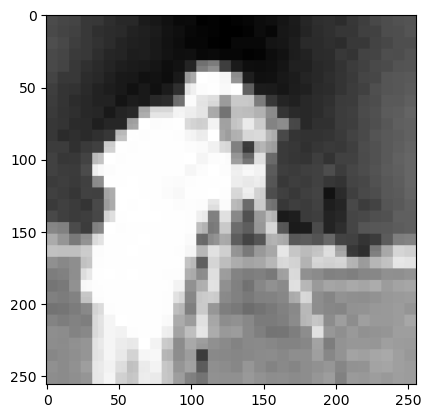

In [128]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

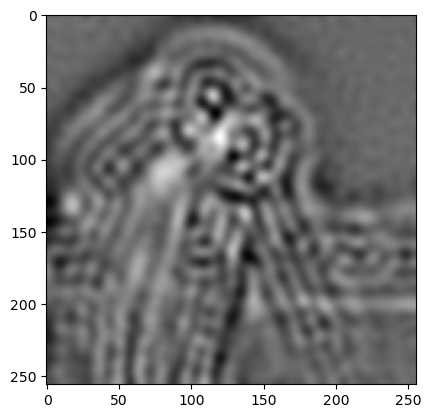

In [129]:
plt.imshow( (vdata["V"][:,5]).reshape(img_shape) , cmap="gray")
plt.show()

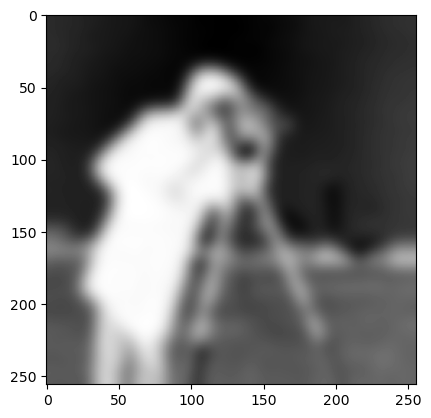

In [130]:
plt.imshow( (data["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

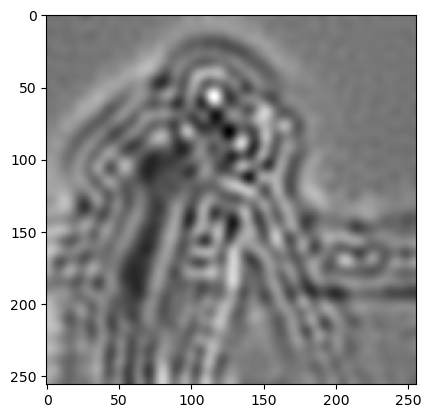

In [131]:
plt.imshow( (data["V"][:,4]).reshape(img_shape) , cmap="gray")
plt.show()

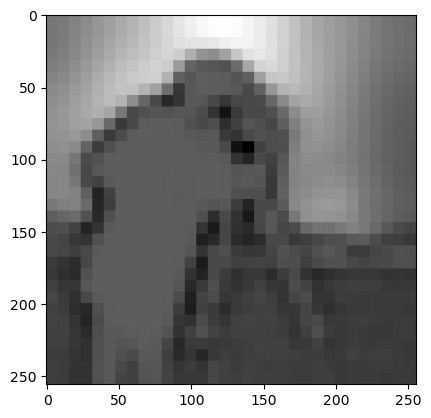

In [132]:
plt.imshow( (mmfkdata["Z"][:,1]).reshape(img_shape) , cmap="gray")
plt.show()

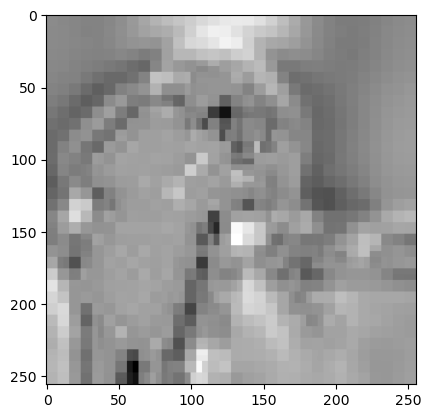

In [133]:
plt.imshow( (mmgkbdata["Lopinv"] @ ( (mmgkbdata["V"][:,4]) ) ).reshape(img_shape) , cmap="gray")
plt.show()

In [134]:
mmgkbdata.keys()

dict_keys(['x', 'V', 'U', 'B', 'w', 'Lopinv', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history', 'haar_history'])